In [1]:
import os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# chdir to project root (folder containing config.yaml)
root = Path.cwd()
while not (root / "config.yaml").exists():
    if root.parent == root:
        raise FileNotFoundError("config.yaml not found above " + str(Path.cwd()))
    root = root.parent
os.chdir(root)

import sys
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
from src.config_loader import load_config

cfg = load_config()
SEED = cfg.modeling.random_seed
print("cwd:", Path.cwd())
print("seed:", SEED, "| model_dir:", cfg.paths.model_dir)
print("min_roi:", cfg.profit_model.min_roi)
print("alpha_op:", cfg.three_way_decision.conformal.alpha_operational,
      "| band:", cfg.three_way_decision.conformal.band_halfwidth)

cwd: d:\Antigravity\Supervised Project\creditlens
seed: 42 | model_dir: models
min_roi: 0.08
alpha_op: 0.1 | band: 0.02


In [2]:
from sklearn.model_selection import train_test_split
from src.train import load_splits

S = load_splits(cfg)
L = pd.read_parquet(cfg.paths.loans_parquet)
TARGET = cfg.target.column
FEATS = [c for c in S["train"].columns if c != TARGET]
banned = list(cfg.leakage_banned_columns)

# evaluation-only columns, index-aligned (never features)
EVAL = {k: L.loc[v.index, ["loan_amnt", "int_rate", "total_pymnt", "issue_d"]]
        for k, v in S.items()}

# crosstab by year
for k, v in S.items():
    yr = EVAL[k]["issue_d"].dt.year
    print(k, v.shape)
    print(pd.crosstab(yr, v[TARGET], margins=True).to_string(), "\n")

# leakage asserts
for k, v in S.items():
    assert v.index.is_unique and v.index.isin(L.index).all(), f"{k}: index misaligned"
    assert v.isna().sum().sum() == 0, f"{k}: nulls"
leaks = [c for c in FEATS if any(b in c for b in banned)]
assert not leaks, f"banned columns in features: {leaks}"
assert not {"int_rate", "total_pymnt", "issue_d"} & set(FEATS)
yrs = {k: set(EVAL[k]["issue_d"].dt.year) for k in S}
assert yrs["cal"] == {2014} and yrs["test"] == {2015}
assert yrs["early_stop"] == {2013} and max(yrs["train"]) <= 2013
assert S["train"].index.intersection(S["early_stop"].index).empty
print("leakage/split asserts: OK | n features:", len(FEATS))

# halve 2014: cal_A (Platt) / cal_B (threshold + conformal + alpha/band)
cal_A, cal_B = train_test_split(S["cal"], test_size=0.5, stratify=S["cal"][TARGET],
                                random_state=SEED)
for name, d in [("cal_A", cal_A), ("cal_B", cal_B)]:
    print(name, d.shape, "default rate", round(d[TARGET].mean(), 4))
print("cal_A/cal_B overlap:", len(cal_A.index.intersection(cal_B.index)))

train (113690, 29)
default      0      1     All
issue_d                      
2007       206     45     251
2008      1315    247    1562
2009      4122    594    4716
2010      7624    842    8466
2011     12602   1499   14101
2012     37567   5903   43470
2013     35890   5234   41124
All      99326  14364  113690 

early_stop (59298, 29)
default      0     1    All
issue_d                    
2013     52154  7144  59298
All      52154  7144  59298 

cal (162570, 29)
default       0      1     All
issue_d                       
2014     140255  22315  162570
All      140255  22315  162570 

test (283026, 29)
default       0      1     All
issue_d                       
2015     240894  42132  283026
All      240894  42132  283026 

leakage/split asserts: OK | n features: 28
cal_A (81285, 29) default rate 0.1373
cal_B (81285, 29) default rate 0.1373
cal_A/cal_B overlap: 0


In [3]:
from src.train import train_lr, evaluate_model

Xtr, ytr = S["train"][FEATS], S["train"][TARGET]
lr = train_lr(Xtr, ytr, cfg)

rows = [evaluate_model(lr, S[k][FEATS], S[k][TARGET], f"LR {name}")
        for k, name in [("train", "train"), ("early_stop", "early_stop"), ("cal", "cal 2014")]]
lr_table = pd.DataFrame(rows).set_index("label").round(4)
print(lr_table.to_string())

coef = pd.Series(lr.coef_[0], index=FEATS).sort_values(key=abs, ascending=False)
print("\ntop 5 |coef| (standardized features):")
print(coef.head(5).round(3).to_string())

               roc_auc  pr_auc   brier  log_loss      ks
label                                                   
LR train        0.6563  0.2064  0.2327    0.6554  0.2280
LR early_stop   0.6445  0.1862  0.2407    0.6728  0.2139
LR cal 2014     0.6459  0.2111  0.2466    0.6853  0.2137

top 5 |coef| (standardized features):
cat__purpose_small_business    0.766
cat__purpose_credit_card      -0.410
num_med__fico_avg             -0.384
num_med__annual_inc           -0.338
cat__purpose_major_purchase   -0.252


Training until validation scores don't improve for 50 rounds
[100]	early_stop's auc: 0.651817	early_stop's binary_logloss: 0.644481
Early stopping, best iteration is:
[124]	early_stop's auc: 0.652419	early_stop's binary_logloss: 0.640213
best_iteration: 124


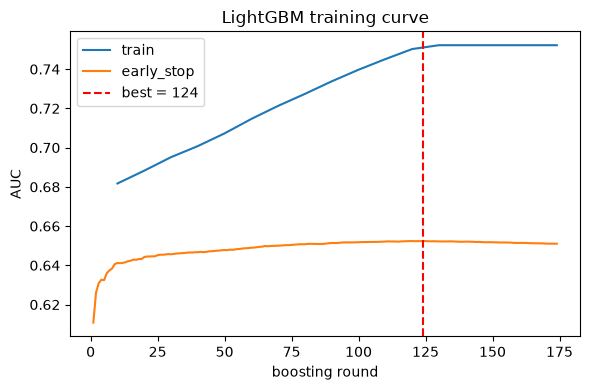

                     roc_auc  pr_auc   brier  log_loss      ks
label                                                         
LR early_stop         0.6445  0.1862  0.2407    0.6728  0.2139
LR cal 2014           0.6459  0.2111  0.2466    0.6853  0.2137
LightGBM early_stop   0.6524  0.1912  0.2260    0.6402  0.2236
LightGBM cal 2014     0.6529  0.2172  0.2323    0.6536  0.2214


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.train import train_lgbm

Xes, yes_ = S["early_stop"][FEATS], S["early_stop"][TARGET]
lgbm = train_lgbm(Xtr, ytr, Xes, yes_, cfg)
print("best_iteration:", lgbm.best_iteration_)

# training curve: early_stop AUC from evals_result_, train AUC computed at checkpoints
es_curve = lgbm.evals_result_["early_stop"]["auc"]
n_it = len(es_curve)
its = sorted(set(list(range(10, n_it + 1, 10)) + [n_it]))
tr_curve = [roc_auc_score(ytr, lgbm.predict_proba(Xtr, num_iteration=i)[:, 1]) for i in its]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(its, tr_curve, label="train")
ax.plot(range(1, n_it + 1), es_curve, label="early_stop")
ax.axvline(lgbm.best_iteration_, color="r", ls="--", label=f"best = {lgbm.best_iteration_}")
ax.set_xlabel("boosting round"); ax.set_ylabel("AUC"); ax.legend(); ax.set_title("LightGBM training curve")
plt.tight_layout(); plt.show()

# LR vs LightGBM (reported, not gated)
rows = []
for name, m in [("LR", lr), ("LightGBM", lgbm)]:
    for k, kn in [("early_stop", "early_stop"), ("cal", "cal 2014")]:
        rows.append(evaluate_model(m, S[k][FEATS], S[k][TARGET], f"{name} {kn}"))
print(pd.DataFrame(rows).set_index("label").round(4).to_string())

            ECE_before  ECE_after  mean_p_before  mean_p_after  observed  brier_after
set                                                                                  
cal_B 2014      0.3334     0.0013         0.4706        0.1377    0.1373       0.1144
test 2015       0.3143     0.0144         0.4631        0.1344    0.1489       0.1221


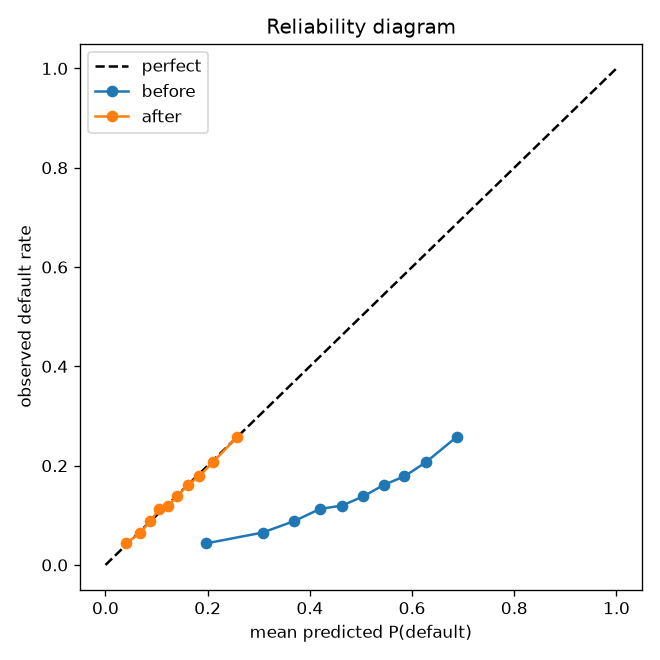

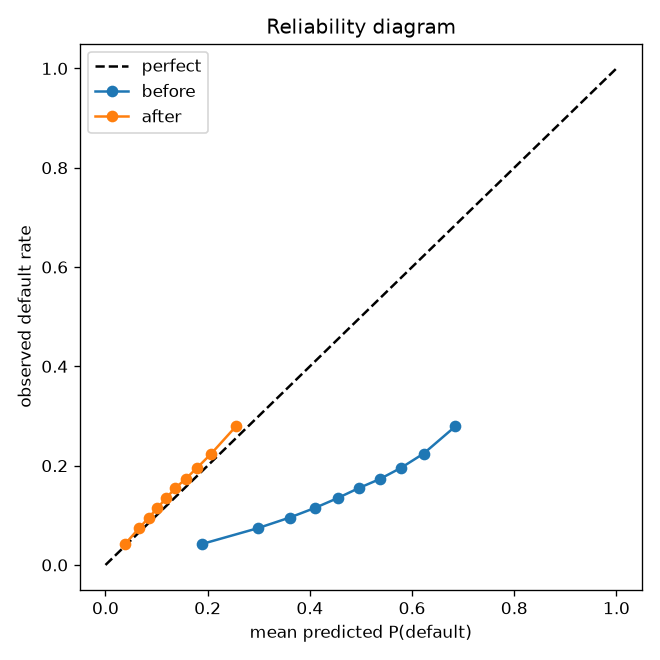

In [5]:
from src.calibrate import calibrate_model, expected_calibration_error, plot_reliability_diagram
from sklearn.metrics import brier_score_loss

cal_model = calibrate_model(lgbm, cal_A[FEATS], cal_A[TARGET], cfg.calibration.method)

res = []
for name, d in [("cal_B 2014", cal_B), ("test 2015", S["test"])]:
    y = d[TARGET].values
    pb = lgbm.predict_proba(d[FEATS])[:, 1]
    pa = cal_model.predict_proba(d[FEATS])[:, 1]
    res.append({"set": name,
                "ECE_before": expected_calibration_error(y, pb),
                "ECE_after": expected_calibration_error(y, pa),
                "mean_p_before": pb.mean(), "mean_p_after": pa.mean(),
                "observed": y.mean(),
                "brier_after": brier_score_loss(y, pa)})
    plot_reliability_diagram(y, pb, pa, f"reports/reliability_{name.split()[0]}_{name.split()[1]}.png")
print(pd.DataFrame(res).set_index("set").round(4).to_string())

from IPython.display import Image, display
display(Image("reports/reliability_cal_B_2014.png"))
display(Image("reports/reliability_test_2015.png"))

THRESH (cal_B): 0.23


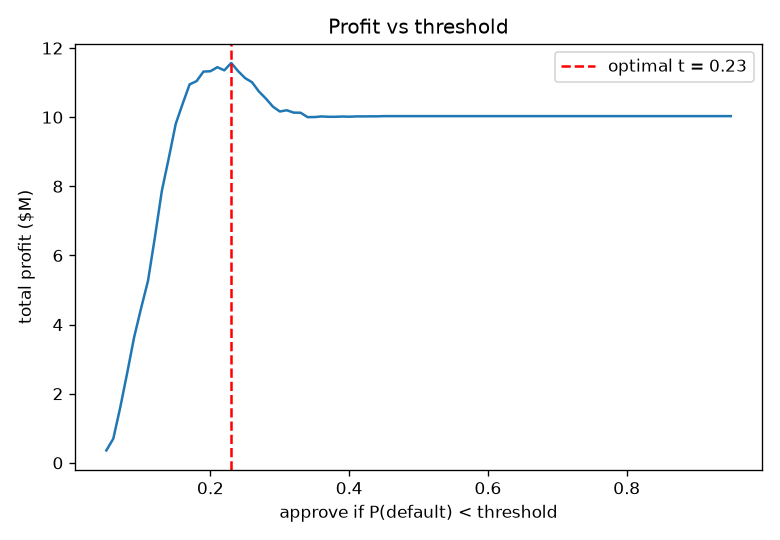

 min_roi  opt_t  approved_share  adj_profit_M
    0.00   0.45           1.000         91.70
    0.06   0.26           0.962         30.72
    0.08   0.23           0.908         11.57
    0.10   0.05           0.073         -1.34
    0.12   0.05           0.073         -3.04
     policy  approved_share  default_rate_approved  raw_profit_M  adj_profit_M
     t=0.23           0.915                 0.1362        229.01        -38.41
      t=0.5           1.000                 0.1489        237.43        -52.51
approve-all           1.000                 0.1489        237.43        -52.51
assumed_apr (mean train int_rate/100): 0.1254


In [6]:
from src.threshold import (compute_profit_per_threshold, select_optimal_threshold,
                           plot_profit_curve)

MIN_ROI = cfg.profit_model.min_roi
SR, SS = cfg.profit_model.sweep_range, cfg.profit_model.sweep_step

def sweep(d, h=MIN_ROI):
    return compute_profit_per_threshold(
        d[TARGET], cal_model.predict_proba(d[FEATS])[:, 1],
        L.loc[d.index, "loan_amnt"], L.loc[d.index, "total_pymnt"], SR, SS, min_roi=h)

dfB = sweep(cal_B)
THRESH = select_optimal_threshold(dfB)          # selected on cal_B only
print("THRESH (cal_B):", THRESH)
plot_profit_curve(dfB, THRESH, "reports/profit_curve_calB.png")
display(Image("reports/profit_curve_calB.png"))

# hurdle sensitivity on cal_B (selection data only)
sens = [{"min_roi": h, "opt_t": select_optimal_threshold(d),
         "approved_share": round(d.loc[d.expected_profit.idxmax(), "n_approved"] / len(cal_B), 3),
         "adj_profit_M": round(d.expected_profit.max() / 1e6, 2)}
        for h in [0, 0.06, 0.08, 0.10, 0.12] for d in [sweep(cal_B, h)]]
print(pd.DataFrame(sens).to_string(index=False))

# 2015 reporting only
dfT = sweep(S["test"])
row = lambda t: dfT.loc[(dfT.threshold - t).abs().idxmin()]
rep = []
for name, t in [(f"t={THRESH}", THRESH), ("t=0.5", 0.5), ("approve-all", 0.95)]:
    r = row(t)
    rep.append({"policy": name, "approved_share": round(r.n_approved / len(S["test"]), 3),
                "default_rate_approved": round(r.n_fp / r.n_approved, 4),
                "raw_profit_M": round(r.raw_profit / 1e6, 2),
                "adj_profit_M": round(r.expected_profit / 1e6, 2)})
print(pd.DataFrame(rep).to_string(index=False))

ASSUMED_APR = float(L.loc[S["train"].index, "int_rate"].mean() / 100)
print("assumed_apr (mean train int_rate/100):", round(ASSUMED_APR, 4))

In [7]:
from src.conformal import (sweep_alpha, build_conformal_model, get_prediction_set,
                           check_oos_rules, decide)

ALPHA_OP = cfg.three_way_decision.conformal.alpha_operational
BAND = cfg.three_way_decision.conformal.band_halfwidth
ALPHAS = list(cfg.three_way_decision.conformal.alpha_sweep)
RULES = cfg.three_way_decision.oos_rules

print(sweep_alpha(cal_model, cal_B[FEATS], cal_B[TARGET], ALPHAS).round(4).to_string(index=False))

pB = cal_model.predict_proba(cal_B[FEATS])[:, 1]
yB = cal_B[TARGET].values
oosB = check_oos_rules(L.loc[cal_B.index], RULES)
psB = get_prediction_set(build_conformal_model(cal_model, cal_B[FEATS], cal_B[TARGET], 1 - ALPHA_OP),
                         cal_B[FEATS])

rows = []
for bw in [0.01, 0.02, 0.03, 0.05]:
    d, _ = decide(pB, psB, oosB, THRESH, bw)
    r = {"band": bw}
    for k in ["Approve", "Reject", "Refer"]:
        m = d == k
        r[k + "_share"] = round(float(m.mean()), 3)
        r[k + "_default"] = round(float(yB[m].mean()), 4)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("chosen: ALPHA_OP =", ALPHA_OP, "| BAND =", BAND, "| THRESH =", THRESH)

 alpha  confidence_level  empirical_coverage  refer_rate
  0.05              0.95                0.95      0.4471
  0.10              0.90                0.90      0.1542
  0.15              0.85                0.85      0.0000
  0.20              0.80                0.80      0.0000
 band  Approve_share  Approve_default  Reject_share  Reject_default  Refer_share  Refer_default
 0.01          0.881           0.1221         0.070          0.2707        0.049         0.2206
 0.02          0.851           0.1189         0.051          0.2817        0.098         0.2214
 0.03          0.846           0.1182         0.038          0.2902        0.117         0.2262
 0.05          0.846           0.1182         0.018          0.3040        0.136         0.2335
chosen: ALPHA_OP = 0.1 | BAND = 0.02 | THRESH = 0.23


In [8]:
import joblib
from sklearn.metrics import roc_auc_score

Path(cfg.paths.model_dir).mkdir(exist_ok=True)
conf_model = build_conformal_model(cal_model, cal_B[FEATS], cal_B[TARGET], 1 - ALPHA_OP)
joblib.dump(conf_model, Path(cfg.paths.model_dir) / "lgbm_conformal.pkl")

T = S["test"]
yT = T[TARGET].values
pT = cal_model.predict_proba(T[FEATS])[:, 1]
psT = get_prediction_set(conf_model, T[FEATS])
oosT = check_oos_rules(L.loc[T.index], RULES)
dec, reason = decide(pT, psT, oosT, THRESH, BAND)

cov = float(psT[np.arange(len(yT)), yT.astype(int)].mean())
print(f"2015 coverage: {cov:.4f} (target {1-ALPHA_OP:.2f}) | both-class sets: {psT.all(axis=1).mean():.4f}")
print("reasons:", pd.Series(reason[reason != ""]).value_counts().to_dict())

profit_raw = (L.loc[T.index, "total_pymnt"] - L.loc[T.index, "loan_amnt"]).values
profit_adj = profit_raw - MIN_ROI * L.loc[T.index, "loan_amnt"].values

rows = []
for name, m in [("threshold only (no Refer)", pT < THRESH), ("after referral: Approve", dec == "Approve")]:
    rows.append({"policy": name, "share": round(m.mean(), 3), "default_rate": round(yT[m].mean(), 4),
                 "raw_profit_M": round(profit_raw[m].sum() / 1e6, 2),
                 "adj_profit_M": round(profit_adj[m].sum() / 1e6, 2)})
print(pd.DataFrame(rows).to_string(index=False))
for k in ["Approve", "Reject", "Refer"]:
    m = dec == k
    print(f"{k}: share {m.mean():.3f} default {yT[m].mean():.4f}")

2015 coverage: 0.8895 (target 0.90) | both-class sets: 0.1441
reasons: {'ambiguous': 25797, 'out-of-support': 7}
                   policy  share  default_rate  raw_profit_M  adj_profit_M
threshold only (no Refer)  0.915        0.1362        229.01        -38.41
  after referral: Approve  0.861        0.1297        221.81        -32.09
Approve: share 0.861 default 0.1297
Reject: share 0.048 default 0.3067
Refer: share 0.091 default 0.2466


In [9]:
import json

mdir = Path(cfg.paths.model_dir)
joblib.dump(lr, mdir / "lr_baseline.pkl")
joblib.dump(lgbm, mdir / "lgbm.pkl")
joblib.dump(cal_model, mdir / "lgbm_calibrated.pkl")

meta_path = mdir / "metadata.json"
meta = json.loads(meta_path.read_text())
audit_before = {k: meta[k] for k in meta if k.startswith("audit_")}

meta.update({
    "random_seed": SEED,
    "lgbm_best_iteration": int(lgbm.best_iteration_),
    "calibration_method": cfg.calibration.method,
    "threshold": float(THRESH),
    "min_roi": float(MIN_ROI),
    "alpha_operational": float(ALPHA_OP),
    "confidence_level": float(1 - ALPHA_OP),
    "band_halfwidth": float(BAND),
    "assumed_apr": float(ASSUMED_APR),
    "oos_rules": {"fico_min": RULES.fico_min, "dti_max": RULES.dti_max,
                  "annual_inc_min": RULES.annual_inc_min, "loan_amnt_max": RULES.loan_amnt_max},
    "report_2015": {
        "coverage": round(cov, 4),
        "both_class_share": round(float(psT.all(axis=1).mean()), 4),
        "approve_share": round(float((dec == "Approve").mean()), 4),
        "refer_share": round(float((dec == "Refer").mean()), 4),
        "reject_share": round(float((dec == "Reject").mean()), 4),
        "auc_calibrated": round(float(roc_auc_score(yT, pT)), 4),
    },
})
meta_path.write_text(json.dumps(meta, indent=2))

# verify
meta2 = json.loads(meta_path.read_text())
required = ["audit_mort_acc", "audit_application_type", "feature_columns", "threshold",
            "alpha_operational", "band_halfwidth", "assumed_apr", "min_roi", "oos_rules"]
missing = [k for k in required if k not in meta2]
assert not missing, f"missing keys: {missing}"
assert all(meta2[k] == v for k, v in audit_before.items()), "audit keys changed"
assert meta2["feature_columns"] == FEATS
for fn in ["preprocessor.pkl", "lr_baseline.pkl", "lgbm.pkl", "lgbm_calibrated.pkl",
           "lgbm_conformal.pkl", "metadata.json"]:
    assert (mdir / fn).exists(), fn
print("saved + metadata OK | keys:", sorted(meta2.keys()))

saved + metadata OK | keys: ['alpha_operational', 'assumed_apr', 'audit_application_type', 'audit_mort_acc', 'band_halfwidth', 'calibration_method', 'confidence_level', 'feature_columns', 'lgbm_best_iteration', 'min_roi', 'oos_rules', 'random_seed', 'report_2015', 'split_default_rates', 'split_sizes', 'threshold']


In [10]:
import shap
import matplotlib.pyplot as plt
from src.explainer import build_tree_explainer, compute_shap_values

bg = S["train"][FEATS].sample(cfg.shap.background_sample_n, random_state=SEED)
explainer = build_tree_explainer(lgbm, bg)
Xs = cal_B[FEATS].sample(2000, random_state=SEED)
sv = compute_shap_values(explainer, Xs)
print("shap shape:", sv.shape)

# aggregate OHE columns back to their source feature
def source(c):
    if c.startswith("cat__home_ownership"): return "home_ownership"
    if c.startswith("cat__purpose"): return "purpose"
    return c.split("__", 1)[1]

src = pd.Series([source(c) for c in FEATS], index=FEATS)
# per-row sum of contributions within each source feature, then mean |.|
agg = pd.DataFrame(sv, columns=FEATS).T.groupby(src).sum().T
imp = agg.abs().mean().sort_values()
print(imp.sort_values(ascending=False).round(4).to_string())

fig, ax = plt.subplots(figsize=(6.5, 5))
imp.plot.barh(ax=ax)
ax.set_xlabel("mean |SHAP| (log-odds, base LightGBM)")
ax.set_title("Feature importance (aggregated to source feature)")
plt.tight_layout(); plt.savefig("reports/shap_bar.png", dpi=120); plt.show()

shap.summary_plot(sv, Xs, show=False, max_display=15)
plt.title("SHAP beeswarm (base LightGBM, cal_B sample)")
plt.tight_layout(); plt.savefig("reports/shap_beeswarm.png", dpi=120); plt.show()

 94%|=================== | 1884/2000 [00:16<00:00]       

shap shape: (2000, 28)
fico_avg                0.2960
annual_inc              0.2773
inq_last_6mths          0.1519
loan_amnt               0.1405
purpose                 0.0904
dti                     0.0876
revol_util              0.0854
open_acc                0.0743
revol_bal               0.0598
total_acc               0.0455
home_ownership          0.0436
credit_history_years    0.0429
emp_length              0.0294
pub_rec                 0.0066
delinq_2yrs             0.0048
